# Level 1 — First steps

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ZetaOne/pyauto-xpp/blob/main/tutorials/worked-examples/01_first-steps.ipynb)

Simulate a model, read its phase plane, find equilibria and their eigenvalues,
handle events (jumps at given conditions), iterate maps, and meet chaos. Each
model is written in Python with `ModelBuilder`, run by XPPAUT through pyauto-xpp
(`pyxpp`), and its numbers are checked against exact or published values.

| | model | what it shows |
|---|---|---|
| [01](#fitzhugh-nagumo) | FitzHugh–Nagumo | phase plane, excitability, Hopf points (exact), periodic orbits |
| [02](#toggle-switch) | genetic toggle switch | bistability, basins, folds and the cusp in $(a_1, a_2)$ |
| [03](#bouncing-ball) | bouncing ball | event times, restitution, Zeno time |
| [04](#integrate-and-fire) | integrate-and-fire with adaptation | exact intervals, f–I curves, rheobase |
| [05](#logistic-map) | logistic map | orbit diagram, Liapunov exponent, period doubling (exact points) |
| [06](#henon-map) | Hénon map | strange attractor, both Liapunov exponents |
| [07](#lorenz) | Lorenz equations | pitchfork and Hopf (exact), Liapunov exponent, Lorenz map |

**How to use this notebook.** Run the cells from the top (the first code cell
sets up helpers used by every section). Each section writes its model file to
`odes/<section>.ode` and its figures to `figures/<section>/`, and ends by
printing its checks. The last cell counts the checks of the whole notebook.

*Models 01–07 are based on examples from XPP Studio (Peter Ashwin and Bard
Ermentrout, GPL-3.0). Every number below is computed by XPPAUT and its AUTO
through pyauto-xpp.*

Running in Google Colab? This cell installs pyauto-xpp first; elsewhere it does nothing.

In [1]:
import sys
if "google.colab" in sys.modules:
    %pip -q install pyauto-xpp --find-links https://github.com/ZetaOne/pyauto-xpp/releases/expanded_assets/v0.4.0

### Setup

`section(name)` starts a section: it sets `FIG` (the figure folder) and `ODE`
(the model file) and opens an empty list of checks. `check(what, value,
expected, tol)` compares a computed number with the expected one and records
the result; `checks_done()` prints the section's score.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from pyxpp.builder import ModelBuilder

HERE = Path.cwd()
plt.rcParams.update({"figure.dpi": 100, "font.size": 11, "axes.titlesize": 12,
                     "legend.fontsize": 9, "savefig.dpi": 130})
results = {}


def section(name):
    """Start a section: its figure folder FIG, its model file ODE and an empty list of checks."""
    global NAME, FIG, ODE
    NAME = name
    FIG = HERE / "figures" / name
    FIG.mkdir(parents=True, exist_ok=True)
    ODE = HERE / "odes" / f"{name}.ode"
    ODE.parent.mkdir(exist_ok=True)
    results[name] = []


def check(what, value, expected, tol):
    ok = abs(value - expected) <= tol
    results[NAME].append(ok)
    print(f"  {'ok  ' if ok else 'FAIL'} {what}: {value:.6g} (expected {expected:.6g})")


def checks_done():
    r = results[NAME]
    print(f"\n{NAME}: {sum(r)}/{len(r)} checks passed")

<a id="fitzhugh-nagumo"></a>
## 01. FitzHugh–Nagumo: an excitable membrane

A two-variable caricature of a neuron: a fast voltage-like variable $v$ with a
cubic nullcline and a slow recovery variable $w$,

$$
\dot v = v - \frac{v^3}{3} - w + i, \qquad \dot w = \varepsilon\,(v + a - b\,w),
$$

with $a = 0.7$, $b = 0.8$, $\varepsilon = 0.08$ and the input current $i$
(first $i = 0.2$). For small $i$ there is one stable rest state, and a spike
only after a big enough kick; as $i$ grows the rest state loses stability in a
Hopf bifurcation and the cell fires repeatedly.

We draw the phase plane, measure the all-or-none response to kicks, and follow
the equilibrium in $i$ with AUTO to find both Hopf points and the branch of
periodic orbits. Look for the cubic $\dot v = 0$ nullcline: the rest state is
stable while it sits on the left (falling) branch.

In [3]:
section("01_fitzhugh-nagumo")

### The model

`ModelBuilder` writes the `.ode` file statement by statement; `render()` shows
it and `load()` writes it to `odes/` and loads it into XPP.

In [4]:
mb = (ModelBuilder("fitzhugh_nagumo")
      .comment("FitzHugh-Nagumo excitable membrane")
      .ode("v", "v-v^3/3-w+i")
      .ode("w", "eps*(v+a-b*w)")
      .parameter(i=0.2, a=0.7, b=0.8, eps=0.08)
      .initial(v=-1.2, w=-0.6)
      .option(total=200, dt=0.05))
print(mb.render())
m = mb.load(ODE)

# FitzHugh-Nagumo excitable membrane
v'=v-v^3/3-w+i
w'=eps*(v+a-b*w)
par i=0.2,a=0.7,b=0.8,eps=0.08
init v=-1.2,w=-0.6
@ total=200,dt=0.05
done



### Phase plane at $i = 0.2$

XPP computes the nullclines and the direction field (its right-hand side on a
grid); `m.equilibrium` runs Newton's method from a guess and returns the
equilibrium with its eigenvalues. A few trajectories (`keep=False` leaves the
model's initial data unchanged) all end at the stable rest state.

equilibrium: <Equilibrium stable V=-1.06939, W=-0.46174> 
  eigenvalues: [-0.10323+0.28011j -0.10323-0.28011j]


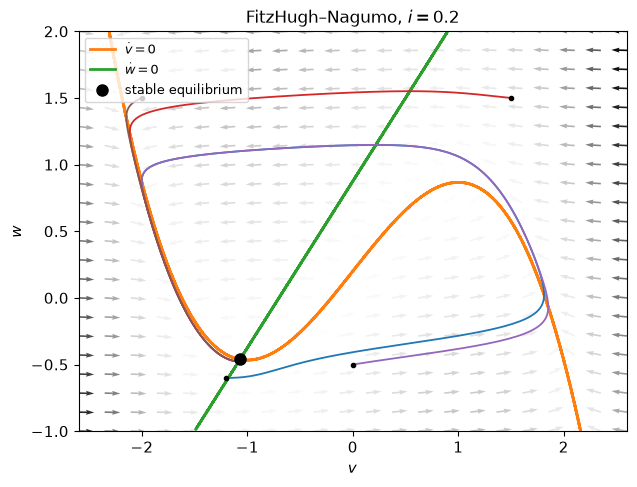

In [5]:
win = (-2.6, 2.6, -1, 2)
nc = m.nullclines(x="v", y="w", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=200)
X, Y, U, V = m.vector_field("v", "w", *win, grid=21)
eq = m.equilibrium({"v": -1.2, "w": -0.6})
print("equilibrium:", eq, "\n  eigenvalues:", np.round(eq.eigenvalues, 5))

fig, ax = plt.subplots(figsize=(6.5, 5))
S = np.hypot(U, V)
ax.quiver(X, Y, U / S, V / S, S, cmap="Greys", scale=35, width=0.003)
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:orange", lw=2, label=r"$\dot v = 0$")
ax.plot(nc["W"][:, 0], nc["W"][:, 1], color="tab:green", lw=2, label=r"$\dot w = 0$")
for (v0, w0), col in zip([(-1.2, -0.6), (0.0, -0.5), (1.5, 1.5), (-2.0, 1.5)],
                         ["tab:blue", "tab:purple", "tab:red", "tab:brown"]):
    tr = m.run(keep=False, v=v0, w=w0)
    ax.plot(tr["v"], tr["w"], lw=1.3, color=col)
    ax.plot(v0, w0, "k.", ms=6)
ax.plot(eq.x["V"], eq.x["W"], "ko", ms=8, label="stable equilibrium")
ax.set(xlim=win[:2], ylim=win[2:], xlabel="$v$", ylabel="$w$", title="FitzHugh–Nagumo, $i = 0.2$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### Excitability

Kick $v$ away from rest by increasing amounts and record the largest $v$
reached. Small kicks decay at once; above a threshold the cell fires a full
spike: an all-or-none response.

spike threshold: a kick of about 0.35 in v


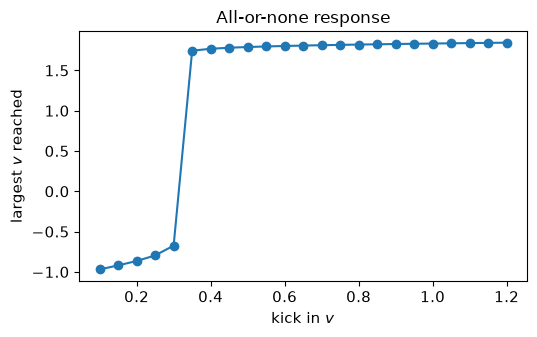

In [6]:
kicks = np.linspace(0.1, 1.2, 23)
peaks = [m.run(keep=False, total=60, v=eq.x["V"] + k, w=eq.x["W"])["v"].max() for k in kicks]
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(kicks, peaks, "o-")
ax.set(xlabel="kick in $v$", ylabel="largest $v$ reached", title="All-or-none response")
fig.tight_layout()
fig.savefig(FIG / "excitability.png")
threshold = kicks[np.argmax(np.array(peaks) > 1.0)]
print(f"spike threshold: a kick of about {threshold:.2f} in v")

### AUTO: equilibria in $i$, Hopf points, periodic orbits

AUTO starts from the current state, so we first settle on the rest state at
$i = 0$ and start the next run where that one ended (`run_last`). Following
the equilibrium in $i$ gives two Hopf points (HB); `m.auto.lyapunov` returns
each one's first Lyapunov coefficient $\ell_1$ (negative: supercritical) and
the frequency $\omega$ at onset. From the first Hopf point we then follow the
periodic orbits.

In [7]:
m.set(i=0.0)
m.run(total=300)
m.run_last(total=10)
eqs = m.auto.run("i", start="steady", ds=0.01, dsmax=0.02, parmin=0, parmax=2, nmax=500)
hbs = eqs.special("HB")
for p in hbs:
    l1, om = m.auto.lyapunov(p)
    print(f"Hopf at i = {p.x:.5f}: l1 = {l1:+.4f} ({'sub' if l1 > 0 else 'super'}critical), "
          f"period at onset {2 * np.pi / om:.3f}")

po = m.auto.run(grab=hbs[0].label, choice="periodic", ntst=60, ds=0.01, dsmax=0.05, nmax=300)
print(f"{len(po)} periodic orbits from the first Hopf point;",
      "folds of orbits at i =", sorted({round(p.x, 4) for p in po.special("LP")}))

Hopf at i = 0.33128: l1 = +0.9719 (subcritical), period at onset 22.806


Hopf at i = 1.41872: l1 = +0.9719 (subcritical), period at onset 22.806


300 periodic orbits from the first Hopf point; folds of orbits at i = [0.3242, 1.4187, 1.4258]


The bifurcation diagram: thick red for stable equilibria, green dots for the
maximum and minimum of $v$ on stable orbits, blue for unstable ones.

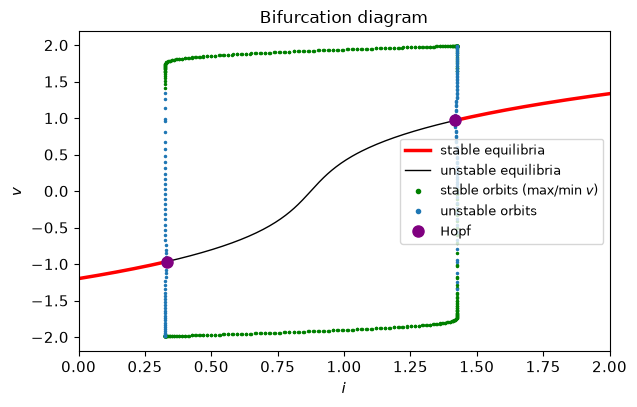

In [8]:
fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs = np.array([p.x for p in eqs])
vs = np.array([p.u0["v"] for p in eqs])
st = np.array([p.stable for p in eqs])
ax.plot(xs, np.where(st, vs, np.nan), "r-", lw=2.5, label="stable equilibria")
ax.plot(xs, np.where(~st, vs, np.nan), "k-", lw=1, label="unstable equilibria")
px = np.array([p.x for p in po])
pst = np.array([p.stable for p in po])
for f in ("umax", "umin"):
    ys = np.array([getattr(p, f)["v"] for p in po])
    ax.plot(px[pst], ys[pst], "g.", ms=3)
    ax.plot(px[~pst], ys[~pst], ".", color="tab:blue", ms=3)
ax.plot([], [], "g.", label="stable orbits (max/min $v$)")
ax.plot([], [], ".", color="tab:blue", label="unstable orbits")
ax.plot([p.x for p in hbs], [p.u0["v"] for p in hbs], "o", color="purple", ms=8, label="Hopf")
ax.set(xlim=(0, 2), xlabel="$i$", ylabel="$v$", title="Bifurcation diagram")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Checks

The Jacobian at an equilibrium is

$$
J = \begin{pmatrix} 1 - v^2 & -1 \\ \varepsilon & -\varepsilon b \end{pmatrix}.
$$

A Hopf point is where its trace vanishes with a positive determinant:
$1 - v^2 = \varepsilon b$, so $v = \mp c$ with $c = \sqrt{1 - \varepsilon b}$.
On the equilibrium curve $w = (v + a)/b$, hence

$$
i_{\mathrm{Hopf}} = \frac{v^3}{3} - v + \frac{v + a}{b}, \qquad v = \mp\sqrt{1 - \varepsilon b},
$$

and the period at onset is $2\pi/\omega$ with
$\omega^2 = \det J = \varepsilon\,\bigl(1 - b\,(1 - c^2)\bigr)$.
We also check the rest state at $i = 0.2$ ($v \approx -1.0692$) and that it is stable.

In [9]:
check("equilibrium v at i = 0.2", eq.x["V"], -1.0692, 1e-3)
check("equilibrium is stable (1 = yes)", float(eq.stable), 1, 0)
a, b, eps = 0.7, 0.8, 0.08
c = np.sqrt(1 - eps * b)
i_hopf = sorted(s * (c**3 / 3 - c + c / b) + a / b for s in (-1, 1))
check("first Hopf point (exact)", hbs[0].x, i_hopf[0], 1e-4)
check("second Hopf point (exact)", hbs[1].x, i_hopf[1], 1e-4)
check("period at onset 2*pi/sqrt(det) (exact)", 2 * np.pi / m.auto.lyapunov(hbs[0])[1],
      2 * np.pi / np.sqrt(eps * (1 - b * (1 - c**2))), 1e-3)
checks_done()

  ok   equilibrium v at i = 0.2: -1.06939 (expected -1.0692)
  ok   equilibrium is stable (1 = yes): 1 (expected 1)
  ok   first Hopf point (exact): 0.331278 (expected 0.331281)
  ok   second Hopf point (exact): 1.41872 (expected 1.41872)


  ok   period at onset 2*pi/sqrt(det) (exact): 22.806 (expected 22.8059)

01_fitzhugh-nagumo: 5/5 checks passed


<a id="toggle-switch"></a>
## 02. Genetic toggle switch: bistability

Two genes repress each other (Gardner, Cantor & Collins 2000):

$$
\dot u = \frac{a_1}{1 + v^{\beta}} - u, \qquad \dot v = \frac{a_2}{1 + u^{\gamma}} - v,
$$

with $\beta = \gamma = 2$ and first $a_1 = a_2 = 3$. With strong enough
repression there are two stable states (one gene on, the other off) separated
by a saddle; which one the cell ends in depends on where it starts. Changing
one gene's synthesis rate $a_1$ removes one of the stable states in a fold
(saddle-node).

We draw the phase plane, colour the basins of attraction, follow the
equilibria in $a_1$ with AUTO to find two folds, and then follow a fold in
$(a_1, a_2)$: the bistable wedge ends in a cusp.

In [10]:
section("02_toggle-switch")

### The model

`m.auto.parameters` lists the parameters AUTO may vary later. XPP's default
Jacobian step ($10^{-3}$) puts errors of about $10^{-3}$ into eigenvalues;
*Numerics → Sing pt ctrl* with a Newton tolerance of $10^{-10}$ and a
finite-difference step of $10^{-8}$ fixes that.

In [11]:
mb = (ModelBuilder("toggle_switch")
      .comment("Genetic toggle switch (Gardner, Cantor & Collins 2000)")
      .ode("u", "a1/(1+v^beta)-u")
      .ode("v", "a2/(1+u^gamma)-v")
      .parameter(a1=3, a2=3, beta=2, gamma=2)
      .initial(u=2.5, v=0.4)
      .option(total=30, dt=0.05))
print(mb.render())
m = mb.load(ODE)
m.auto.parameters("a1", "a2", "beta", "gamma")
m.buttons.numerics.sing_pt_ctrl(500, 1e-10, 1e-8)

# Genetic toggle switch (Gardner, Cantor & Collins 2000)
u'=a1/(1+v^beta)-u
v'=a2/(1+u^gamma)-v
par a1=3,a2=3,beta=2,gamma=2
init u=2.5,v=0.4
@ total=30,dt=0.05
done



'prompt  Maximum iterates : [100] -> 500\nprompt  Newton tolerance : [0.001] -> 1e-10\nprompt  Jacobian epsilon : [0.001] -> 1e-08\n'

### Phase plane at $a_1 = a_2 = 3$

Three equilibria: two stable nodes and a saddle on the diagonal $u = v$.
Trajectories are coloured by the state they end in.

equilibria at a1 = a2 = 3:
  u = 2.61803, v = 0.38197, eigenvalues [-0.33333 -1.66667], stable node
  u = 1.21341, v = 1.21341, eigenvalues [ 0.19106 -2.19106], saddle
  u = 0.38197, v = 2.61803, eigenvalues [-1.66667 -0.33333], stable node


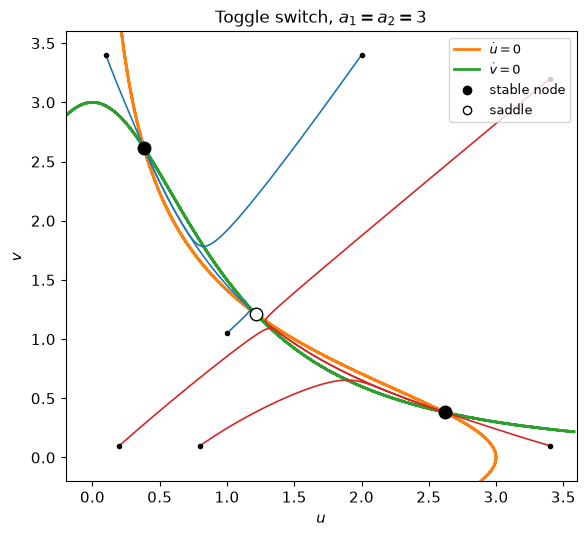

In [12]:
win = (-0.2, 3.6, -0.2, 3.6)
nc = m.nullclines(x="u", y="v", xlo=win[0], xhi=win[1], ylo=win[2], yhi=win[3], mesh=200)
eqs = [m.equilibrium(g) for g in ({"u": 2.6, "v": 0.4}, {"u": 1.2, "v": 1.2}, {"u": 0.4, "v": 2.6})]
print("equilibria at a1 = a2 = 3:")
for e in eqs:
    print(f"  u = {e.x['U']:.5f}, v = {e.x['V']:.5f}, eigenvalues {np.round(e.eigenvalues.real, 5)}, "
          f"{'stable node' if e.stable else 'saddle'}")

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.plot(nc["U"][:, 0], nc["U"][:, 1], color="tab:orange", lw=2, label=r"$\dot u = 0$")
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:green", lw=2, label=r"$\dot v = 0$")
for u0, v0 in [(0.2, 0.1), (3.4, 3.2), (0.1, 3.4), (3.4, 0.1), (2.0, 3.4), (0.8, 0.1), (1.0, 1.05)]:
    tr = m.run(keep=False, u=u0, v=v0, total=30)
    ax.plot(tr["u"], tr["v"], color="tab:red" if tr["u"][-1] > tr["v"][-1] else "tab:blue", lw=1.2)
    ax.plot(u0, v0, "k.", ms=6)
for e in eqs:
    ax.plot(e.x["U"], e.x["V"], "o", mfc="k" if e.stable else "white", mec="k", ms=9)
ax.plot([], [], "ko", label="stable node")
ax.plot([], [], "o", mfc="white", mec="k", label="saddle")
ax.set(xlim=win[:2], ylim=win[2:], xlabel="$u$", ylabel="$v$", title="Toggle switch, $a_1 = a_2 = 3$")
ax.legend(loc="upper right")
fig.tight_layout()
fig.savefig(FIG / "phase_plane.png")

### Basins of attraction

Run from every point of a $36 \times 36$ grid and record which gene is on at
the end. The boundary between the two basins is the saddle's stable manifold,
here the diagonal $u = v$ (starts exactly on it go to the saddle).

starts ending with u on: 630, with v on: 630, on the saddle (the diagonal u = v): 36


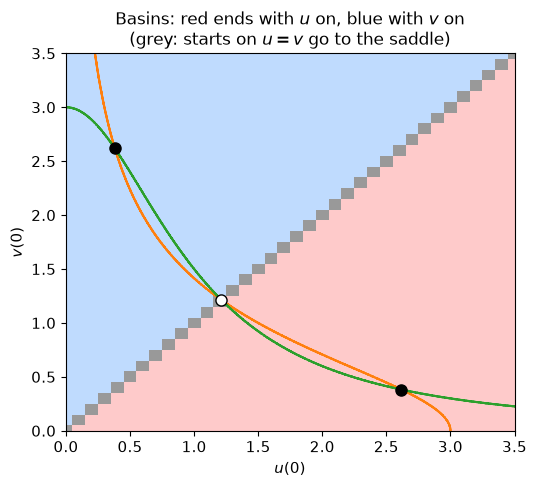

In [13]:
from matplotlib.colors import ListedColormap

g = np.linspace(0, 3.5, 36)
ends = np.array([[[m.run(keep=False, u=a, v=b, total=40)[x][-1] for x in "uv"] for a in g] for b in g])
diff = ends[..., 0] - ends[..., 1]
basin = np.select([diff > 0.5, diff < -0.5], [1, -1], 0)
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.pcolormesh(g, g, basin, cmap=ListedColormap(["#bfdbfe", "0.6", "#fecaca"]),
              vmin=-1.5, vmax=1.5, shading="nearest")
ax.plot(nc["U"][:, 0], nc["U"][:, 1], color="tab:orange", lw=1.5)
ax.plot(nc["V"][:, 0], nc["V"][:, 1], color="tab:green", lw=1.5)
for e in eqs:
    ax.plot(e.x["U"], e.x["V"], "o", mfc="k" if e.stable else "white", mec="k", ms=8)
ax.set(xlim=(0, 3.5), ylim=(0, 3.5), xlabel="$u(0)$", ylabel="$v(0)$",
       title="Basins: red ends with $u$ on, blue with $v$ on\n(grey: starts on $u = v$ go to the saddle)")
fig.tight_layout()
fig.savefig(FIG / "basins.png")
n_u, n_v, n_s = (basin == 1).sum(), (basin == -1).sum(), (basin == 0).sum()
frac = n_u / (n_u + n_v)
print(f"starts ending with u on: {n_u}, with v on: {n_v}, on the saddle (the diagonal u = v): {n_s}")

### AUTO: equilibria in $a_1$ (with $a_2 = 3$)

We follow the $u$-on state in $a_1$ upwards, then (after `m.auto.reset()`,
since a second run from scratch replaces the diagram, and putting $a_1$ back to
3) downwards. The downward branch turns twice at folds (LP); between them the
switch is bistable.

AUTO, folds in a1 (a2 = 3): [2.70079, 3.54241]


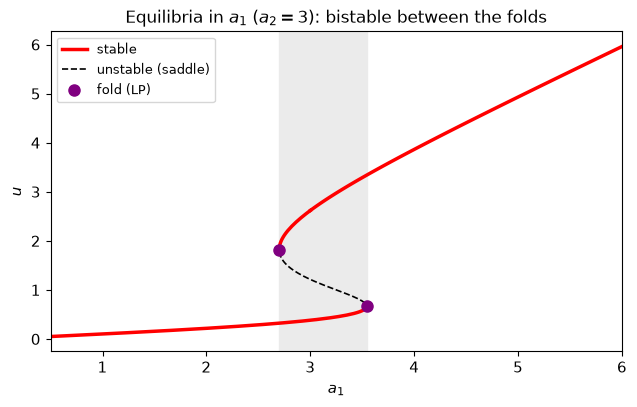

In [14]:
m.run(total=100)
m.run_last(total=10)
up = m.auto.run("a1", start="steady", ds=0.01, dsmax=0.05, parmin=0.5, parmax=6, nmax=2000)
m.auto.reset()
m.set(a1=3)
m.run(total=100)
m.run_last(total=10)
eqd = m.auto.run("a1", start="steady", ds=-0.01, dsmax=0.05, parmin=0.5, parmax=6, nmax=2000)
lps = sorted(eqd.special("LP"), key=lambda p: p.x)
print("AUTO, folds in a1 (a2 = 3):", [round(p.x, 5) for p in lps])

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for d, lab in ((eqd, True), (up, False)):
    xs = np.array([p.x for p in d])
    us = np.array([p.u0["u"] for p in d])
    st = np.array([bool(p.stable) for p in d])
    ax.plot(xs, np.where(st, us, np.nan), "r-", lw=2.5, label="stable" if lab else None)
    ax.plot(xs, np.where(~st, us, np.nan), "k--", lw=1.2, label="unstable (saddle)" if lab else None)
ax.plot([p.x for p in lps], [p.u0["u"] for p in lps], "o", color="purple", ms=8, label="fold (LP)")
ax.axvspan(lps[0].x, lps[1].x, color="0.92", zorder=0)
ax.set(xlim=(0.5, 6), xlabel="$a_1$", ylabel="$u$",
       title="Equilibria in $a_1$ ($a_2 = 3$): bistable between the folds")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### AUTO: the fold in $(a_1, a_2)$

Grabbing a fold point and giving a second parameter (`param2="a2"`) follows the
fold curve, once in each direction. The two curves meet at a cusp.

fold curve: 345 points; cusp near (a1, a2) = (2.0000, 2.0000)


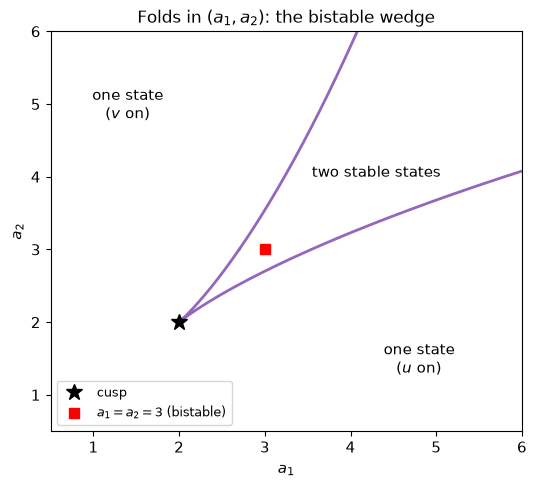

In [15]:
c1 = m.auto.run(grab=lps[0].label, param2="a2", ds=0.01, dsmax=0.05, parmin=0.5, parmax=6, nmax=2000)
c2 = m.auto.run(grab=lps[0].label, ds=-0.01)
fold_a1 = np.concatenate([[q.x for q in c] for c in (c1, c2)])
fold_a2 = np.concatenate([[q.par["a2"] for q in c] for c in (c1, c2)])
k = np.argmin(fold_a1 + fold_a2)
print(f"fold curve: {len(fold_a1)} points; cusp near (a1, a2) = ({fold_a1[k]:.4f}, {fold_a2[k]:.4f})")

fig, ax = plt.subplots(figsize=(5.5, 5))
for c in (c1, c2):
    ax.plot([q.x for q in c], [q.par["a2"] for q in c], color="tab:purple", lw=2)
ax.plot(fold_a1[k], fold_a2[k], "k*", ms=12, label="cusp")
ax.plot(3, 3, "rs", ms=7, label="$a_1 = a_2 = 3$ (bistable)")
ax.text(4.3, 4.0, "two stable states", ha="center")
ax.text(1.4, 4.8, "one state\n($v$ on)", ha="center")
ax.text(4.8, 1.3, "one state\n($u$ on)", ha="center")
ax.set(xlim=(0.5, 6), ylim=(0.5, 6), xlabel="$a_1$", ylabel="$a_2$",
       title="Folds in $(a_1, a_2)$: the bistable wedge")
ax.legend(loc="lower left")
fig.tight_layout()
fig.savefig(FIG / "two_parameter.png")

### Checks

At $a_1 = a_2 = 3$ (and $\beta = \gamma = 2$):

* The saddle is $u = v = s$ with $s^3 + s - 3 = 0$. There the Jacobian has
  $-1$ on the diagonal and $-q$, $q = 2s^2/(1+s^2)$, off it, so the unstable
  eigenvalue is $-1 + q = -1 + 2s^2/(1+s^2)$.
* For the asymmetric states, $u = 3/(1+v^2)$ and $v = 3/(1+u^2)$ give
  $uv = 1$ and $u + v = 3$, so $u = (3 + \sqrt5)/2$. The product of the
  off-diagonal entries is $4/\bigl((1+u^2)(1+v^2)\bigr) = 4/9$, so the
  eigenvalues are $-1 \pm 2/3$: the slowest is $-1/3$.
* The model is symmetric under $u \leftrightarrow v$, and so is the grid: half
  the starts end with $u$ on, and the 36 starts on the diagonal reach the saddle.
* Folds: $\det J = 0$ gives $4u^2v^2 = (1+u^2)(1+v^2)$. With
  $a_2 = v(1+u^2)$ this becomes $a_2 = 4v^3/(3v^2 - 1)$, so for $a_2 = 3$

$$
4v^3 - 9v^2 + 3 = 0, \qquad u^2 = \frac{1+v^2}{3v^2-1}, \qquad a_1 = u\,(1+v^2).
$$

* Cusp: on $u = v$ the fold condition $4u^4 = (1+u^2)^2$ gives $u = 1$, so
  $a_1 = a_2 = 2$.

In [16]:
s = np.roots([1, 0, 1, -3]).real.max()
check("saddle u = v (root of s^3+s-3)", eqs[1].x["U"], s, 1e-6)
check("saddle unstable eigenvalue -1+2s^2/(1+s^2)", eqs[1].eigenvalues.real.max(),
      -1 + 2 * s**2 / (1 + s**2), 1e-5)
check("stable node u = (3+sqrt5)/2", eqs[0].x["U"], (3 + np.sqrt(5)) / 2, 1e-6)
check("stable node eigenvalue -1/3 (exact)", eqs[0].eigenvalues.real.max(), -1 / 3, 1e-6)
check("basins are mirror images (fraction with u on)", frac, 0.5, 1e-12)
check("starts on the diagonal that reach the saddle", n_s, len(g), 0)
vr = np.array([r.real for r in np.roots([4, -9, 0, 3]) if abs(r.imag) < 1e-12 and 3 * r.real**2 > 1])
a1_exact = sorted(np.sqrt((1 + vr**2) / (3 * vr**2 - 1)) * (1 + vr**2))
check("first fold a1 (exact)", lps[0].x, a1_exact[0], 1e-4)
check("second fold a1 (exact)", lps[1].x, a1_exact[1], 1e-4)
check("cusp a1 (exact 2)", fold_a1[k], 2.0, 0.02)
check("cusp a2 (exact 2)", fold_a2[k], 2.0, 0.02)
checks_done()

  ok   saddle u = v (root of s^3+s-3): 1.21341 (expected 1.21341)
  ok   saddle unstable eigenvalue -1+2s^2/(1+s^2): 0.191059 (expected 0.191059)
  ok   stable node u = (3+sqrt5)/2: 2.61803 (expected 2.61803)
  ok   stable node eigenvalue -1/3 (exact): -0.333333 (expected -0.333333)
  ok   basins are mirror images (fraction with u on): 0.5 (expected 0.5)
  ok   starts on the diagonal that reach the saddle: 36 (expected 36)
  ok   first fold a1 (exact): 2.70079 (expected 2.70079)
  ok   second fold a1 (exact): 3.54241 (expected 3.54241)
  ok   cusp a1 (exact 2): 2 (expected 2)
  ok   cusp a2 (exact 2): 2 (expected 2)

02_toggle-switch: 10/10 checks passed


<a id="bouncing-ball"></a>
## 03. Bouncing ball: global events

A ball dropped from height $h = 2$ falls under gravity,

$$
\dot x = v, \qquad \dot v = -g, \qquad g = 9.81 .
$$

A `global` event fires whenever $x$ crosses 0 going down: it puts the ball
back on the floor and reverses its velocity with a coefficient of restitution
$e = 0.85$,

$$
x \mapsto 0, \qquad v \mapsto -e\,v .
$$

Each flight is shorter than the one before by the factor $e$, so infinitely
many bounces fit into a finite time (a *Zeno point*), after which the ball
lies still.

We read the impact times from XPP's output, compare flight times, energies and
the time to come to rest with the closed-form answers, and see how the
accuracy of XPP's event location depends on the time step.

In [17]:
section("03_bouncing-ball")

### The model

`global_event(-1, "x", {...})` fires when $x$ crosses 0 downwards and applies
the jumps. A small time step ($dt = 0.0002$) keeps the event times accurate
(see the last step).

In [18]:
g, e, h = 9.81, 0.85, 2.0
mb = (ModelBuilder("bouncing_ball")
      .comment("ball bouncing on the floor; the global event is the impact")
      .ode("x", "v")
      .ode("v", "-g")
      .global_event(-1, "x", {"x": 0, "v": "-e*v"})
      .parameter(g=g, e=e)
      .initial(x=h, v=0)
      .option(total=9, dt=0.0002))
print(mb.render())
m = mb.load(ODE)

# ball bouncing on the floor; the global event is the impact
x'=v
v'=-g
global -1 x {x=0;v=-e*v}
par g=9.81,e=0.85
init x=2.0,v=0
@ total=9,dt=0.0002
done



### A run

The first fall lasts $t_1 = \sqrt{2h/g}$, and flight $n$ (after bounce $n$)
lasts $2e^n t_1$, so the ball comes to rest at

$$
T = t_1 + 2t_1\,(e + e^2 + \dots) = t_1\,\frac{1+e}{1-e}.
$$

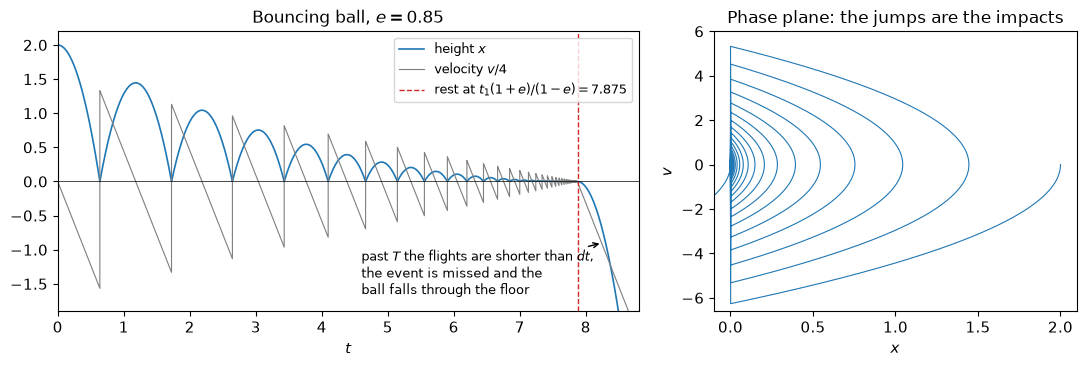

In [19]:
tr = m.run()
t, x, v = tr.t, tr["x"], tr["v"]
t1 = np.sqrt(2 * h / g)
T_rest = t1 * (1 + e) / (1 - e)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.6, 1]})
axs[0].plot(t, x, lw=1.2, label="height $x$")
axs[0].plot(t, v / 4, lw=0.8, color="tab:gray", label="velocity $v/4$")
axs[0].axvline(T_rest, color="tab:red", ls="--", lw=1, label=f"rest at $t_1(1+e)/(1-e) = {T_rest:.3f}$")
axs[0].axhline(0, color="k", lw=0.5)
axs[0].annotate("past $T$ the flights are shorter than $dt$,\nthe event is missed and the\nball falls through the floor",
                xy=(8.25, -0.9), xytext=(4.6, -1.65), fontsize=9, arrowprops=dict(arrowstyle="->"))
axs[0].set(xlim=(0, 8.8), ylim=(-1.9, 2.2), xlabel="$t$", title=f"Bouncing ball, $e = {e}$")
axs[0].legend(loc="upper right")
axs[1].plot(x, v, lw=0.8)
axs[1].set(xlim=(-0.1, 2.1), ylim=(-6.6, 6), xlabel="$x$", ylabel="$v$",
           title="Phase plane: the jumps are the impacts")
fig.tight_layout()
fig.savefig(FIG / "bounces.png")

### Impact times

XPP stops the step at the crossing, applies the jump, and writes the next
output point. Between impacts the motion is exactly ballistic, so from the
first output point after an impact, $(x_k, v_k)$ at $t_k$, the time $s$ since
the impact solves $x_k = v_k s + g s^2/2$. The last few bounces (closer than
0.1 to $T$) cannot be resolved and are left out. Flight times and energies
$E = v^2/2 + g x$ should shrink by $e$ and $e^2$ per bounce, and the impact
times follow

$$
t_n = t_1 + 2t_1\,(e + \dots + e^{n-1}) = t_1\,\frac{1 + e - 2e^n}{1 - e}.
$$

27 impacts resolved; first ones at [0.63855 1.72409 2.64679 3.43109 4.09775 4.6644 ]
flight ratios: [0.85 0.85 0.85 0.85 0.85 0.85 0.85]
energy ratios: [0.7225 0.7225 0.7225 0.7225 0.7225 0.7225 0.7225] (e^2 = 0.7225)


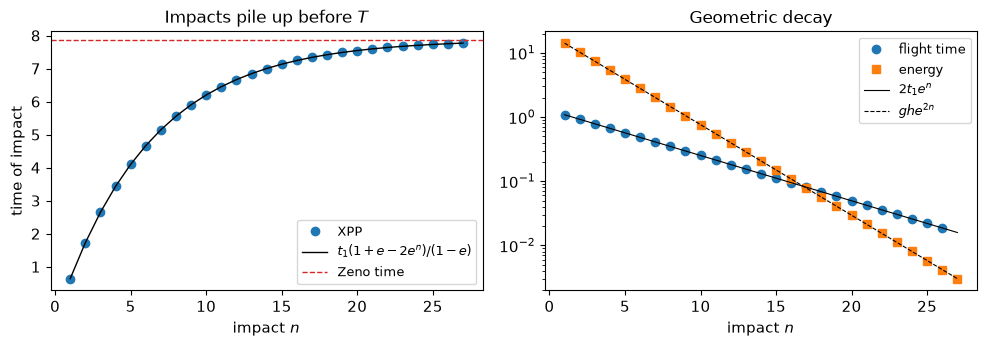

In [20]:
k = np.where(np.diff(v) > 0)[0] + 1
k = k[t[k] < T_rest - 0.1]
s = (-v[k] + np.sqrt(v[k] ** 2 + 2 * g * x[k])) / g
impacts = t[k] - s
flights = np.diff(impacts)
energy = 0.5 * v[k] ** 2 + g * x[k]
print(f"{len(impacts)} impacts resolved; first ones at", np.round(impacts[:6], 5))
print("flight ratios:", np.round(flights[1:8] / flights[:7], 5))
print("energy ratios:", np.round(energy[1:8] / energy[:7], 5), f"(e^2 = {e**2:.4f})")

n = np.arange(1, len(impacts) + 1)
exact = t1 * (1 + e - 2 * e ** n) / (1 - e)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
axs[0].plot(n, impacts, "o", label="XPP")
axs[0].plot(n, exact, "k-", lw=1, label="$t_1(1 + e - 2e^n)/(1 - e)$")
axs[0].axhline(T_rest, color="tab:red", ls="--", lw=1, label="Zeno time")
axs[0].set(xlabel="impact $n$", ylabel="time of impact", title="Impacts pile up before $T$")
axs[0].legend()
axs[1].semilogy(n[:-1], flights, "o", label="flight time")
axs[1].semilogy(n, energy, "s", label="energy")
axs[1].semilogy(n, 2 * t1 * e ** n, "k-", lw=0.8, label="$2t_1e^n$")
axs[1].semilogy(n, g * h * e ** (2 * n), "k--", lw=0.8, label="$ghe^{2n}$")
axs[1].set(xlabel="impact $n$", title="Geometric decay")
axs[1].legend()
fig.tight_layout()
fig.savefig(FIG / "impacts.png")

The simulation's own estimate of the rest time is the last resolved impact
plus the geometric tail of the remaining flights,
$\text{(last flight)}\times(e + e^2 + \dots) = \text{(last flight)}\times e/(1-e)$.

In [21]:
T_sim = impacts[-1] + flights[-1] * e / (1 - e)
print(f"rest time from the impacts: {T_sim:.6f}; exact {T_rest:.6f}")

rest time from the impacts: 7.875441; exact 7.875461


### How accurate is XPP's event location?

XPP finds the crossing inside a step by interpolation, so impact times carry
an error that shrinks like $dt^2$: a five times smaller $dt$ gives an error
about 25 times smaller. This is why the model uses $dt = 0.0002$.

In [22]:
print("error of the 10th impact time against the exact value:")
for dt in (0.01, 0.002, 0.0004):
    r = m.run(keep=False, dt=dt)
    kk = np.where(np.diff(r["v"]) > 0)[0][9] + 1
    ss = (-r["v"][kk] + np.sqrt(r["v"][kk] ** 2 + 2 * g * r["x"][kk])) / g
    print(f"  dt = {dt:<7} error = {r.t[kk] - ss - exact[9]:+.2e}")

error of the 10th impact time against the exact value:


  dt = 0.01    error = -1.79e-03


  dt = 0.002   error = -5.75e-05


  dt = 0.0004  error = -2.01e-06


### Checks

The first impact at $t_1 = \sqrt{2h/g}$; the ratio of successive flight times
$e$ and of energies $e^2$ (means over 10 bounces); the tenth impact time
$t_{10} = t_1(1 + e - 2e^{10})/(1-e)$; and the time to rest
$T = t_1(1+e)/(1-e)$.

In [23]:
check("first impact at sqrt(2h/g) (exact)", impacts[0], t1, 1e-6)
check("flight time ratio, mean of 10 (exact e)", np.mean(flights[1:11] / flights[:10]), e, 1e-5)
check("energy ratio per bounce, mean of 10 (exact e^2)", np.mean(energy[1:11] / energy[:10]), e**2, 1e-5)
check("tenth impact time (exact)", impacts[9], exact[9], 1e-5)
check("time to rest from the impacts vs t1(1+e)/(1-e)", T_sim, T_rest, 1e-4)
checks_done()

  ok   first impact at sqrt(2h/g) (exact): 0.638551 (expected 0.638551)
  ok   flight time ratio, mean of 10 (exact e): 0.85 (expected 0.85)
  ok   energy ratio per bounce, mean of 10 (exact e^2): 0.7225 (expected 0.7225)
  ok   tenth impact time (exact): 6.19927 (expected 6.19927)
  ok   time to rest from the impacts vs t1(1+e)/(1-e): 7.87544 (expected 7.87546)

03_bouncing-ball: 5/5 checks passed


<a id="integrate-and-fire"></a>
## 04. Integrate-and-fire neuron with adaptation

The voltage $v$ charges towards the input $i$ with time constant $\tau$; an
adaptation current $w$ decays with the slower time constant $\tau_w$:

$$
\tau\,\dot v = -v + i - w, \qquad \tau_w\,\dot w = -w .
$$

When $v$ reaches the threshold 1 a `global` event resets it and kicks $w$ up
by $b$:

$$
v = 1 \;\Longrightarrow\; v \mapsto 0, \quad w \mapsto w + b .
$$

Parameters: $\tau = 1$, $\tau_w = 20$, $b = 0.2$, $i = 1.6$. Each spike makes
the next one come later, until the intervals settle at a steady rhythm.

We compute the steady interval exactly and compare it with XPP's, check the
interval without adaptation, and draw the f–I curves (firing rate against
input) with and without adaptation.

In [24]:
section("04_integrate-and-fire")

### The model

In [25]:
tau, tauw, b, i0 = 1.0, 20.0, 0.2, 1.6
mb = (ModelBuilder("integrate_and_fire")
      .comment("leaky integrate-and-fire neuron with spike-triggered adaptation")
      .ode("v", "(-v+i-w)/tau")
      .ode("w", "-w/tauw")
      .global_event(1, "v-1", {"v": 0, "w": "w+b"})
      .parameter(i=i0, tau=tau, tauw=tauw, b=b)
      .initial(v=0, w=0)
      .option(total=200, dt=0.001, maxstor=300000))
print(mb.render())
m = mb.load(ODE)

# leaky integrate-and-fire neuron with spike-triggered adaptation
v'=(-v+i-w)/tau
w'=-w/tauw
global 1 v-1 {v=0;w=w+b}
par i=1.6,tau=1.0,tauw=20.0,b=0.2
init v=0,w=0
@ total=200,dt=0.001,maxstor=300000
done



Spike times: the first output point after each reset, moved back by the time
$v$ needs to climb from 0 to its value there (just after a reset
$\dot v \approx (i - w)/\tau$).

In [26]:
def spike_times(tr, i):
    k = np.where(np.diff(tr["v"]) < -0.5)[0] + 1
    return tr.t[k] - tau * tr["v"][k] / (i - tr["w"][k])

### Adaptation: intervals lengthen and settle

In the steady state, just after a reset $w = W$ with
$W = W e^{-T/\tau_w} + b$, so $W = b/(1 - e^{-T/\tau_w})$. Solving the
$v$ equation from $v(0) = 0$,

$$
v(t) = i\,\bigl(1 - e^{-t/\tau}\bigr) - \frac{W\tau_w}{\tau_w - \tau}\bigl(e^{-t/\tau_w} - e^{-t/\tau}\bigr),
$$

and the steady interval $T$ is the root of $v(T) = 1$, found below by
bisection (`steady_isi`).

36 spikes; first intervals [1.2399 1.67   2.505  4.2704 5.7936] ... last 6.03158


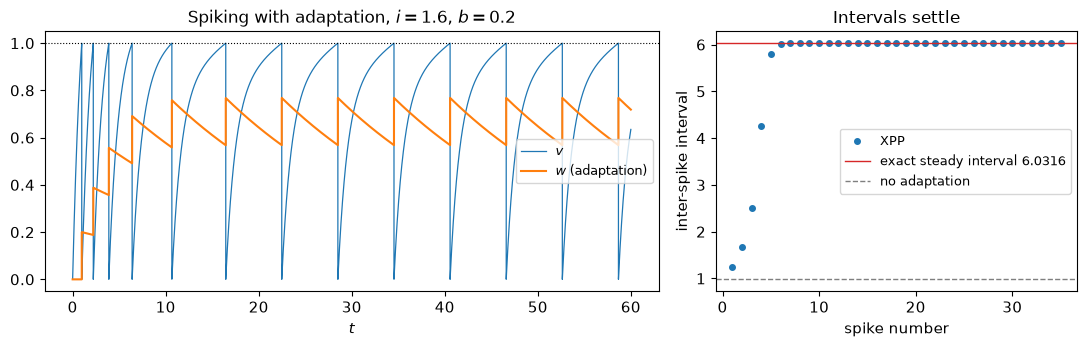

In [27]:
tr = m.run()
sp = spike_times(tr, i0)
isi = np.diff(sp)
print(f"{len(sp)} spikes; first intervals", np.round(isi[:5], 4), "... last", np.round(isi[-1], 5))


def steady_isi(i, b):
    def f(T):
        W = b / (1 - np.exp(-T / tauw)) if b > 0 else 0.0
        return i * (1 - np.exp(-T / tau)) - W * tauw / (tauw - tau) * (np.exp(-T / tauw) - np.exp(-T / tau)) - 1
    lo, hi = 1e-6, 1e4
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        lo, hi = (lo, mid) if f(mid) > 0 else (mid, hi)
    return 0.5 * (lo + hi)


T_ad = steady_isi(i0, b)

fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.7, 1]})
sel = tr.t <= 60
axs[0].plot(tr.t[sel], tr["v"][sel], lw=0.9, label="$v$")
axs[0].plot(tr.t[sel], tr["w"][sel], lw=1.5, label="$w$ (adaptation)")
axs[0].axhline(1, color="k", ls=":", lw=0.8)
axs[0].set(xlabel="$t$", title=f"Spiking with adaptation, $i = {i0}$, $b = {b}$")
axs[0].legend(loc="center right")
axs[1].plot(np.arange(1, len(isi) + 1), isi, "o", ms=4, label="XPP")
axs[1].axhline(T_ad, color="tab:red", lw=1, label=f"exact steady interval {T_ad:.4f}")
axs[1].axhline(tau * np.log(i0 / (i0 - 1)), color="tab:gray", ls="--", lw=1, label="no adaptation")
axs[1].set(xlabel="spike number", ylabel="inter-spike interval", title="Intervals settle")
axs[1].legend()
fig.tight_layout()
fig.savefig(FIG / "adaptation.png")

### No adaptation

With $b = 0$, $v(t) = i\,(1 - e^{-t/\tau})$ reaches 1 at

$$
T_0 = \tau \ln\frac{i}{i-1}.
$$

In [28]:
tr0 = m.run(keep=False, b=0, total=40)
isi0 = np.diff(spike_times(tr0, i0))
print(f"b = 0: intervals {np.round(isi0[:4], 6)}, exact {tau * np.log(i0 / (i0 - 1)):.6f}")

b = 0: intervals [0.980829 0.98083  0.980829 0.98083 ], exact 0.980829


### f–I curves

The steady firing rate on a grid of inputs, with and without adaptation.
Near $i = 1$ the adapted interval is long (about 62 at $i = 1.01$), so each run
waits 400 time units and then measures over 400.

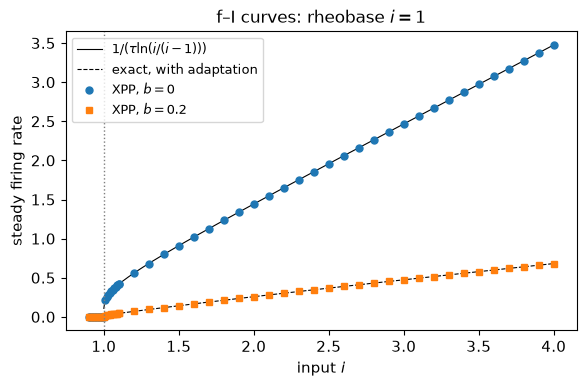

In [29]:
I = np.round(np.concatenate([np.arange(0.9, 1.1, 0.01), np.linspace(1.1, 4, 30)]), 10)
rates = {}
for bb in (0.0, b):
    r = []
    for i in I:
        t_ = spike_times(m.run(keep=False, i=i, b=bb, total=800, trans=400, dt=0.002), i)
        r.append(1 / np.mean(np.diff(t_)) if len(t_) > 1 else 0.0)
    rates[bb] = np.array(r)

Ifine = np.linspace(1.0001, 4, 400)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(Ifine, 1 / (tau * np.log(Ifine / (Ifine - 1))), "k-", lw=0.8, label=r"$1/(\tau\ln(i/(i-1)))$")
ax.plot(Ifine, [1 / steady_isi(i, b) for i in Ifine], "k--", lw=0.8, label="exact, with adaptation")
ax.plot(I, rates[0.0], "o", ms=5, label="XPP, $b = 0$")
ax.plot(I, rates[b], "s", ms=5, label=f"XPP, $b = {b}$")
ax.axvline(1, color="tab:gray", ls=":", lw=1)
ax.set(xlabel="input $i$", ylabel="steady firing rate", title="f–I curves: rheobase $i = 1$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "f_I.png")

### Checks

* The interval without adaptation, $\tau\ln\bigl(i/(i-1)\bigr)$, and the
  steady interval with adaptation (the root of $v(T) = 1$ above).
* The rheobase: for $i \le 1$ the rest state $v = i$ lies below threshold, and
  for any $i > 1$ the cell fires. Adaptation cannot move it, because $w$ decays
  to 0 while the cell is silent. On the grid of step 0.01 the largest silent
  input is therefore 1 and the smallest firing one 1.01, with and without
  adaptation.
* The rate at $i = 3$: $1/\ln(3/2)$ without adaptation, $1/T$ with it.

In [30]:
check("interval without adaptation, tau ln(i/(i-1)) (exact)", np.mean(isi0), tau * np.log(i0 / (i0 - 1)), 1e-5)
check("steady interval with adaptation (exact)", isi[-1], T_ad, 1e-4)
for bb in (0.0, b):
    check(f"rheobase, b = {bb}: largest silent i on the 0.01 grid (exact 1)", I[rates[bb] == 0].max(), 1.0, 1e-9)
    check(f"rheobase, b = {bb}: smallest firing i on the 0.01 grid (exact 1.01)", I[rates[bb] > 0].min(), 1.01, 1e-9)
k = np.argmin(abs(I - 3.0))
check("rate at i = 3, b = 0: 1/ln(3/2) (exact)", rates[0.0][k], 1 / np.log(I[k] / (I[k] - 1)), 1e-4)
check("rate at i = 3, adapted (exact)", rates[b][k], 1 / steady_isi(I[k], b), 1e-4)
checks_done()

  ok   interval without adaptation, tau ln(i/(i-1)) (exact): 0.980829 (expected 0.980829)
  ok   steady interval with adaptation (exact): 6.03158 (expected 6.03158)
  ok   rheobase, b = 0.0: largest silent i on the 0.01 grid (exact 1): 1 (expected 1)
  ok   rheobase, b = 0.0: smallest firing i on the 0.01 grid (exact 1.01): 1.01 (expected 1.01)
  ok   rheobase, b = 0.2: largest silent i on the 0.01 grid (exact 1): 1 (expected 1)
  ok   rheobase, b = 0.2: smallest firing i on the 0.01 grid (exact 1.01): 1.01 (expected 1.01)
  ok   rate at i = 3, b = 0: 1/ln(3/2) (exact): 2.4663 (expected 2.4663)
  ok   rate at i = 3, adapted (exact): 0.47372 (expected 0.47372)

04_integrate-and-fire: 8/8 checks passed


<a id="logistic-map"></a>
## 05. The logistic map: period doubling to chaos

$$
x_{n+1} = r\,x_n\,(1 - x_n),
$$

the simplest map with chaos. The fixed point $x^* = 1 - 1/r$ loses stability
at $r = 3$ when its multiplier $r(1 - 2x^*) = 2 - r$ passes $-1$; a period-2
orbit takes over, then period 4 at $r = 1 + \sqrt6$, then 8, 16, …,
accumulating near $r_\infty = 3.5699$, after which most $r$ give chaos, broken
by periodic windows.

We draw the orbit diagram with the Liapunov exponent below it, locate the
second doubling from the exponent, follow the fixed point with AUTO, and use
XPP's own Liapunov exponent at $r = 4$.

In [31]:
section("05_logistic-map")

### The model

`map("x", ...)` together with `meth="discrete"` makes XPP iterate
$x_{n+1} = r x_n (1 - x_n)$ instead of integrating. Two helpers: `orbit`
returns $n$ iterates after a transient of `trans` (the output's time column is
the iterate number), and `liapunov` averages $\ln|f'(x_n)| = \ln|r(1 - 2x_n)|$
along an orbit.

In [32]:
mb = (ModelBuilder("logistic_map")
      .comment("the logistic map")
      .map("x", "r*x*(1-x)")
      .parameter(r=3.7)
      .initial(x=0.5)
      .option(total=300, meth="discrete"))
print(mb.render())
m = mb.load(ODE)


def orbit(r, n=400, trans=1000, x0=0.3):
    return m.run(keep=False, total=trans + n, trans=trans, r=r, x=x0)["x"][1:]


def liapunov(r, n=4000, trans=2000):
    x = orbit(r, n, trans)
    return np.mean(np.log(np.abs(r * (1 - 2 * x))))

# the logistic map
x(t+1)=r*x*(1-x)
par r=3.7
init x=0.5
@ total=300,meth=discrete
done



### Orbit diagram and Liapunov exponent

1500 values of $r$, 250 iterates each. The exponent is negative on periodic
orbits, touches 0 at each doubling, and is positive in chaos. Dotted lines mark
the doublings at $3$, $1+\sqrt6$, $3.544090$ and the accumulation point
$r_\infty$.

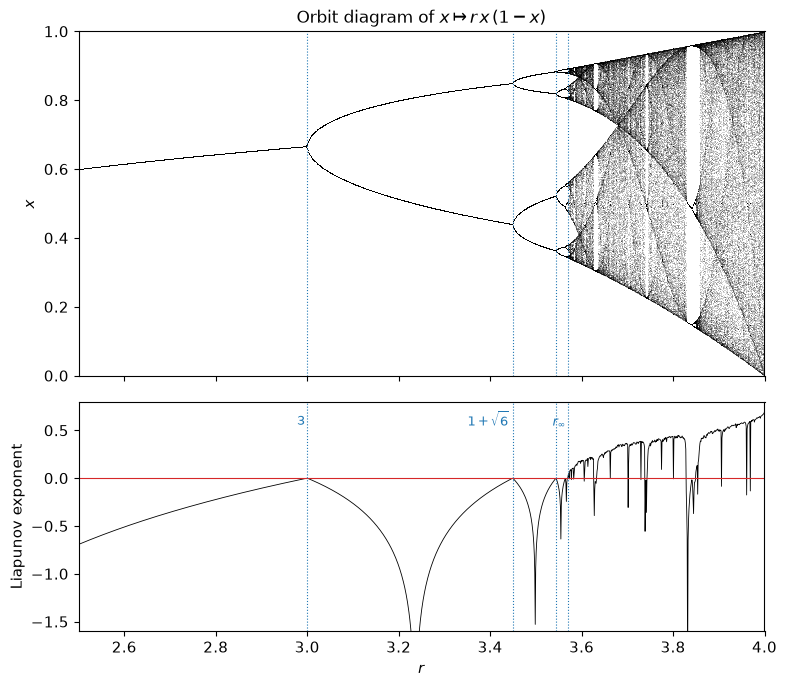

In [33]:
R = np.linspace(2.5, 4, 1500)
lam = np.array([liapunov(r) for r in R])
r_pd = [3, 1 + np.sqrt(6), 3.544090, 3.569946]

fig, axs = plt.subplots(2, 1, figsize=(8, 7), sharex=True, gridspec_kw={"height_ratios": [1.5, 1]})
P = np.repeat(R, 250)
X = np.concatenate([orbit(r, 250) for r in R])
axs[0].scatter(P, X, s=0.25, c="k", marker=".", lw=0)
axs[0].set(ylabel="$x$", ylim=(0, 1), title=r"Orbit diagram of $x \mapsto r\,x\,(1 - x)$")
axs[1].plot(R, lam, "k-", lw=0.6)
axs[1].axhline(0, color="tab:red", lw=0.8)
for r in r_pd:
    for ax in axs:
        ax.axvline(r, color="tab:blue", ls=":", lw=0.8)
for r, lab in zip(r_pd, ["$3$", r"$1+\sqrt{6}$", "", r"$r_\infty$"]):
    axs[1].text(r - 0.005, 0.55, lab, ha="right", fontsize=9, color="tab:blue")
axs[1].set(xlabel="$r$", ylabel="Liapunov exponent", ylim=(-1.6, 0.8), xlim=(2.5, 4))
fig.tight_layout()
fig.savefig(FIG / "orbit_diagram.png", dpi=150)

Zoom onto the second doubling: the exponent rises to 0 at $r_2$ and falls
again, so its largest value on a fine grid locates $r_2$.

In [34]:
Rz = np.linspace(3.43, 3.47, 401)
lamz = np.array([liapunov(r, n=4000, trans=40000) for r in Rz])
r2 = Rz[np.argmax(lamz)]
print(f"period 2 -> 4: exponent largest (closest to 0) at r = {r2:.4f}; 1 + sqrt(6) = {1 + np.sqrt(6):.4f}")

period 2 -> 4: exponent largest (closest to 0) at r = 3.4495; 1 + sqrt(6) = 3.4495


### AUTO: the fixed point and its loss of stability

Start AUTO from the fixed point reached at $r = 2.8$. For a map, AUTO's HB
label marks a multiplier leaving the unit circle; here it leaves through $-1$.
Then XPP's own Liapunov exponent (*Numerics → stocHast → Liapunov*) on a long
orbit at $r = 4$.

In [35]:
m.run(r=2.8)
m.run_last()
d = m.auto.run("r", start="steady", ds=0.01, dsmax=0.02, parmin=2.5, parmax=4, nmax=200, epss=1e-7)
hb = d.special("HB")[0]
mu = hb.eigenvalues[0]
print(f"AUTO: fixed point x = {hb.u0['X']:.6f} loses stability at r = {hb.x:.7f}, multiplier {mu.real:.6f}")

m.run(r=4, x=0.3, total=20000)
m.buttons.numerics.stochast.liapunov(0)
msg = m.transcript.strip().splitlines()[-1]
lam_xpp = float(msg.split()[-1])
print("XPP at r = 4:", msg.split("message")[-1].strip())

AUTO: fixed point x = 0.666667 loses stability at r = 3.0000000, multiplier -1.000000


XPP at r = 4: Maximal exponent is 0.692979


### Checks

* AUTO: the fixed point $x^* = 1 - 1/r$ loses stability at $r = 3$ (where
  $x^* = 2/3$) with multiplier $-1$.
* Below $r = 3$ the orbit sits on the fixed point, so the exponent is
  $\ln|2 - r|$; at $r = 2.8$ that is $\ln 0.8$.
* The period-2 points are the roots of $r^2x^2 - r(r+1)x + (r+1) = 0$, so the
  multiplier of the 2-cycle is

$$
r^2(1 - 2x_1)(1 - 2x_2) = 4 + 2r - r^2,
$$

  which is $-1$ at $r = 1 + \sqrt6$ (checked at $r = 3.3$, and the onset of
  period 4 found from the exponent above).
* At $r = 4$, $x = \sin^2\theta$ turns the map into $\theta \mapsto 2\theta$, so
  the exponent is $\ln 2$ (from the orbit and from XPP).

XPP stores trajectories in single precision (about 7 digits), hence
tolerances of $10^{-6}$.

In [36]:
check("AUTO: fixed point loses stability at r = 3 (exact)", hb.x, 3.0, 1e-6)
check("AUTO: multiplier there is -1 (exact)", mu.real, -1.0, 1e-6)
check("AUTO: fixed point there, 1 - 1/r = 2/3 (exact)", hb.u0["X"], 2 / 3, 1e-6)
check("exponent at r = 2.8 from the orbit, ln|2 - r| (exact)", liapunov(2.8), np.log(0.8), 1e-6)
x12 = orbit(3.3, 2)
check("period-2 multiplier at r = 3.3 from the orbit, 4 + 2r - r^2 (exact)",
      np.prod(3.3 * (1 - 2 * x12)), 4 + 2 * 3.3 - 3.3**2, 1e-6)
check("onset of period 4 from the exponent, 1 + sqrt(6) (exact; grid step 1e-4)", r2, 1 + np.sqrt(6), 1e-4)
check("exponent at r = 4 from the orbit, ln 2 (exact; sampling error ~0.01)", liapunov(4, n=200000), np.log(2), 0.01)
check("XPP's Liapunov exponent at r = 4, ln 2 (exact)", lam_xpp, np.log(2), 0.01)
checks_done()

  ok   AUTO: fixed point loses stability at r = 3 (exact): 3 (expected 3)
  ok   AUTO: multiplier there is -1 (exact): -1 (expected -1)
  ok   AUTO: fixed point there, 1 - 1/r = 2/3 (exact): 0.666667 (expected 0.666667)


  ok   exponent at r = 2.8 from the orbit, ln|2 - r| (exact): -0.223144 (expected -0.223144)


  ok   period-2 multiplier at r = 3.3 from the orbit, 4 + 2r - r^2 (exact): -0.29 (expected -0.29)
  ok   onset of period 4 from the exponent, 1 + sqrt(6) (exact; grid step 1e-4): 3.4495 (expected 3.44949)


  ok   exponent at r = 4 from the orbit, ln 2 (exact; sampling error ~0.01): 0.693147 (expected 0.693147)
  ok   XPP's Liapunov exponent at r = 4, ln 2 (exact): 0.692979 (expected 0.693147)

05_logistic-map: 8/8 checks passed


<a id="henon-map"></a>
## 06. The Hénon map: a strange attractor

$$
x_{n+1} = 1 - a\,x_n^2 + y_n, \qquad y_{n+1} = b\,x_n,
$$

with $a = 1.4$, $b = 0.3$. The map stretches and folds the plane while
shrinking areas by the constant factor $|\det J| = |b|$, so orbits settle on an
attractor of zero area. At these values the attractor is a fractal (Hénon
1976); as $a$ grows from 0 it is reached through a cascade of period doublings.

We find the two fixed points, draw the attractor, compute both Liapunov
exponents (and XPP's largest one), and draw the orbit diagram in $a$.

In [37]:
section("06_henon-map")

### The model

`bound=100` lets XPP stop an orbit that runs off to infinity.

In [38]:
a, b = 1.4, 0.3
mb = (ModelBuilder("henon_map")
      .comment("the Henon map")
      .map("x", "1-a*x^2+y")
      .map("y", "b*x")
      .parameter(a=a, b=b)
      .initial(x=0, y=0)
      .option(total=100000, meth="discrete", bound=100))
print(mb.render())
m = mb.load(ODE)

# the Henon map
x(t+1)=1-a*x^2+y
y(t+1)=b*x
par a=1.4,b=0.3
init x=0,y=0
@ total=100000,meth=discrete,bound=100
done



### Fixed points

A fixed point has $x = 1 - a x^2 + b x$, i.e. $a x^2 + (1-b)x - 1 = 0$:

$$
x_\pm = \frac{-(1-b) \pm \sqrt{(1-b)^2 + 4a}}{2a}, \qquad y_\pm = b\,x_\pm .
$$

XPP's defaults (Newton tolerance and Jacobian step both $10^{-3}$) give the
fixed point to about 7 digits but the multipliers only to about 3, since they
come from a finite-difference Jacobian with step $10^{-3}|x|$; we tighten both.

In [39]:
xs = [(-(1 - b) + s * np.sqrt((1 - b) ** 2 + 4 * a)) / (2 * a) for s in (1, -1)]
m.set(newt_tol=1e-6, jac_eps=1e-7)
fps = [m.equilibrium({"x": x, "y": b * x + 0.01}) for x in xs]
for fp in fps:
    print(f"fixed point ({fp.x['X']:.8f}, {fp.x['Y']:.8f}), multipliers {np.round(fp.eigenvalues.real, 6)}")

fixed point (0.63135448, 0.18940634), multipliers [-1.923739  0.155946]
fixed point (-1.13135448, -0.33940634), multipliers [ 3.259822 -0.09203 ]


### The attractor and its Liapunov exponents

100000 iterates from $(0, 0)$. XPP's Liapunov exponent perturbs each stored
point by the Jacobian step and iterates it once; the stored orbit has single
precision (about $10^{-7}$), so that step must stay well above it: back to
$10^{-3}$.

Both exponents also come from the orbit itself: carry two tangent vectors along
with the Jacobian

$$
J(x_n) = \begin{pmatrix} -2a x_n & 1 \\ b & 0 \end{pmatrix}
$$

and re-orthonormalise them every step (QR); the averages of $\ln|R_{ii}|$ are
$\lambda_1$ and $\lambda_2$. The Kaplan–Yorke dimension is
$1 + \lambda_1/|\lambda_2|$.

XPP: Maximal exponent is 0.419631


from the orbit: exponents 0.41983, -1.62380; sum -1.203973, ln b = -1.203973
Kaplan-Yorke dimension 1 + lam1/|lam2| = 1.2585


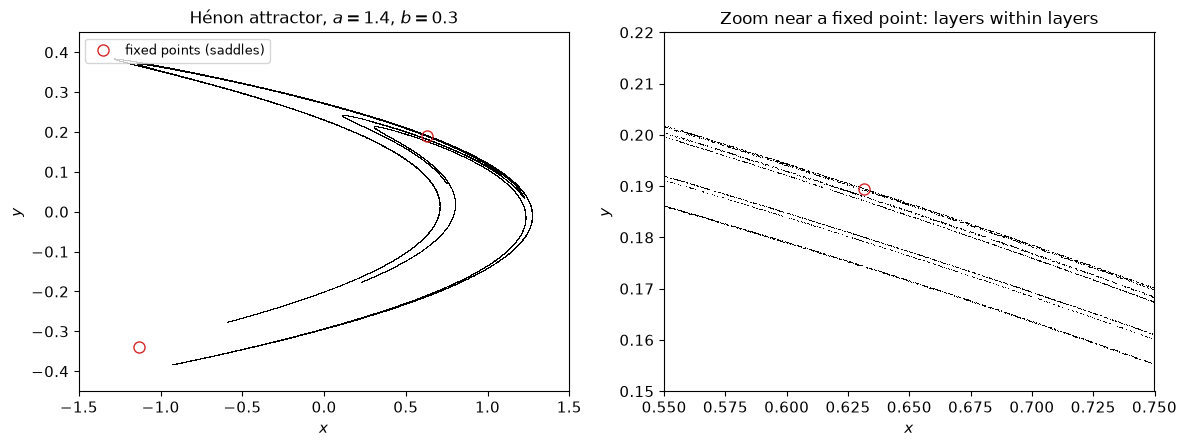

In [40]:
tr = m.run()
x, y = tr["x"][100:], tr["y"][100:]
m.set(jac_eps=1e-3)
m.buttons.numerics.stochast.liapunov(0)
msg = m.transcript.strip().splitlines()[-1]
lam_xpp = float(msg.split()[-1])
print("XPP:", msg.split("message")[-1].strip())

Q, sums = np.eye(2), np.zeros(2)
for xn in x:
    Q, R = np.linalg.qr(np.array([[-2 * a * xn, 1.0], [b, 0.0]]) @ Q)
    sums += np.log(np.abs(np.diag(R)))
lam1, lam2 = sums / len(x)
print(f"from the orbit: exponents {lam1:.5f}, {lam2:.5f}; sum {lam1 + lam2:.6f}, ln b = {np.log(b):.6f}")
print(f"Kaplan-Yorke dimension 1 + lam1/|lam2| = {1 + lam1 / abs(lam2):.4f}")

fig, axs = plt.subplots(1, 2, figsize=(12, 4.6))
for ax, lim in zip(axs, [(-1.5, 1.5, -0.45, 0.45), (0.55, 0.75, 0.15, 0.22)]):
    ax.plot(x, y, ",k")
    ax.plot([f.x["X"] for f in fps], [f.x["Y"] for f in fps], "o", mfc="none", mec="tab:red", ms=8,
            label="fixed points (saddles)")
    ax.set(xlim=lim[:2], ylim=lim[2:], xlabel="$x$", ylabel="$y$")
axs[0].set_title(f"Hénon attractor, $a = {a}$, $b = {b}$")
axs[0].legend(loc="upper left")
axs[1].set_title("Zoom near a fixed point: layers within layers")
fig.tight_layout()
fig.savefig(FIG / "attractor.png", dpi=150)

### Orbit diagram in $a$ (with $b = 0.3$)

The fixed point with $x > 0$ has multipliers solving
$\mu^2 + 2ax\,\mu - b = 0$. Putting $\mu = -1$ gives $1 - 2ax - b = 0$, i.e.
$x = (1-b)/(2a)$, and on the fixed-point curve this happens at

$$
a_{\mathrm{PD}} = \frac{3}{4}(1-b)^2 .
$$

After the diagram we compute the multiplier there with a tight Jacobian step.

<pyxpp.Model 06_henon-map.ode: vars=['X', 'Y'] aux=[] pars=2>

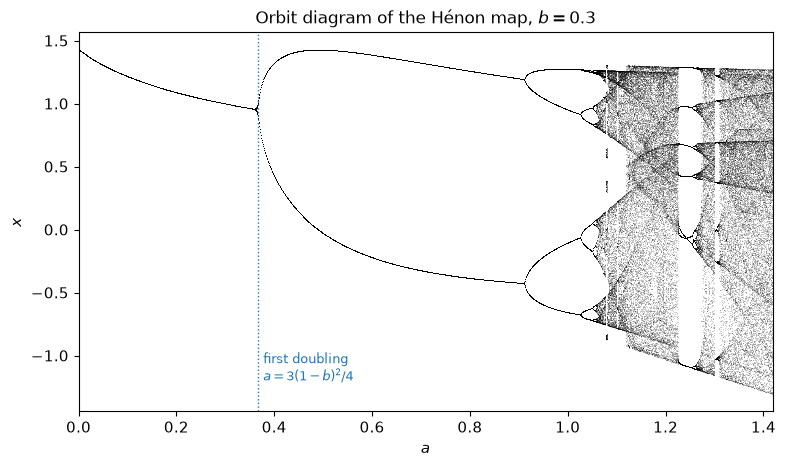

In [41]:
a_pd = 3 * (1 - b) ** 2 / 4
A = np.linspace(0, 1.42, 1400)
P = np.repeat(A, 200)
X = np.concatenate([m.run(keep=False, a=aa, x=0, y=0, total=700, trans=500)["x"][1:] for aa in A])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.scatter(P, X, s=0.3, c="k", marker=".", lw=0)
ax.axvline(a_pd, color="tab:blue", ls=":", lw=1)
ax.text(a_pd + 0.01, -1.2, "first doubling\n$a = 3(1-b)^2/4$", fontsize=9, color="tab:blue")
ax.set(xlim=(0, 1.42), xlabel="$a$", ylabel="$x$", title="Orbit diagram of the Hénon map, $b = 0.3$")
fig.tight_layout()
fig.savefig(FIG / "orbit_diagram.png", dpi=150)

m.set(a=a_pd, jac_eps=1e-7)
mu_pd = m.equilibrium({"x": (1 - b) / (2 * a_pd), "y": b * (1 - b) / (2 * a_pd)}).eigenvalues.real.min()
m.set(a=a)

### Checks

* Both fixed points against $x_\pm$ above.
* The product of the multipliers is $\det J = -b$ at every point.
* The multiplier $-1$ at $a_{\mathrm{PD}} = 3(1-b)^2/4$.
* The largest Liapunov exponent, about $0.419$ in the literature, from XPP and
  from the orbit; and the sum of both exponents, which must equal
  $\ln|\det J| = \ln b$ exactly.

In [42]:
check("fixed point x+ (exact)", fps[0].x["X"], xs[0], 1e-8)
check("fixed point x- (exact)", fps[1].x["X"], xs[1], 1e-8)
check("product of multipliers = det J = -b (exact)", np.prod(fps[0].eigenvalues).real, -b, 1e-8)
check("multiplier -1 at the first doubling a = 3(1-b)^2/4 (exact)", mu_pd, -1.0, 1e-6)
check("XPP's largest Liapunov exponent (literature 0.419)", lam_xpp, 0.419, 0.01)
check("largest exponent from the orbit (literature 0.419)", lam1, 0.419, 0.01)
check("sum of the exponents = ln b (exact)", lam1 + lam2, np.log(b), 1e-9)
checks_done()

  ok   fixed point x+ (exact): 0.631354 (expected 0.631354)
  ok   fixed point x- (exact): -1.13135 (expected -1.13135)
  ok   product of multipliers = det J = -b (exact): -0.3 (expected -0.3)
  ok   multiplier -1 at the first doubling a = 3(1-b)^2/4 (exact): -1 (expected -1)
  ok   XPP's largest Liapunov exponent (literature 0.419): 0.419631 (expected 0.419)
  ok   largest exponent from the orbit (literature 0.419): 0.419829 (expected 0.419)
  ok   sum of the exponents = ln b (exact): -1.20397 (expected -1.20397)

06_henon-map: 7/7 checks passed


<a id="lorenz"></a>
## 07. The Lorenz equations: a strange attractor

Lorenz's three-variable model of convection: $x$ is the speed of the rolls,
$y$ and $z$ temperature differences,

$$
\dot x = s\,(y - x), \qquad \dot y = r x - y - x z, \qquad \dot z = x y - b z,
$$

with $s = 10$, $b = 8/3$ and first $r = 27$. For $r < 1$ the fluid is at
rest; at $r = 1$ two steady rolls appear in a pitchfork; they lose stability
in a Hopf bifurcation near $r = 24.74$, and at $r = 27$ the orbit switches
irregularly between the two wings of the butterfly.

We draw the attractor, follow the equilibria in $r$ with AUTO, estimate the
largest Lyapunov exponent from the separation of nearby orbits, and draw
Lorenz's return map of successive maxima of $z$.

In [43]:
section("07_lorenz")

### The model

$b$ is written as $2.666667$, as XPP Studio does.

In [44]:
s, b = 10, 2.666667
mb = (ModelBuilder("lorenz")
      .comment("Lorenz equations")
      .ode("x", "s*(-x+y)")
      .ode("y", "r*x-y-x*z")
      .ode("z", "-b*z+x*y")
      .parameter(r=27, s=s, b=b)
      .initial(x=-7.5, y=-3.6, z=30)
      .option(total=40, dt=0.01, meth="rk4", bound=1000))
print(mb.render())
m = mb.load(ODE)

# Lorenz equations
x'=s*(-x+y)
y'=r*x-y-x*z
z'=-b*z+x*y
par r=27,s=10,b=2.666667
init x=-7.5,y=-3.6,z=30
@ total=40,dt=0.01,meth=rungekutta,bound=1000
done



### The attractor at $r = 27$

The black dots are the two steady rolls
$x = y = \pm\sqrt{b(r-1)}$, $z = r - 1$, both unstable here.

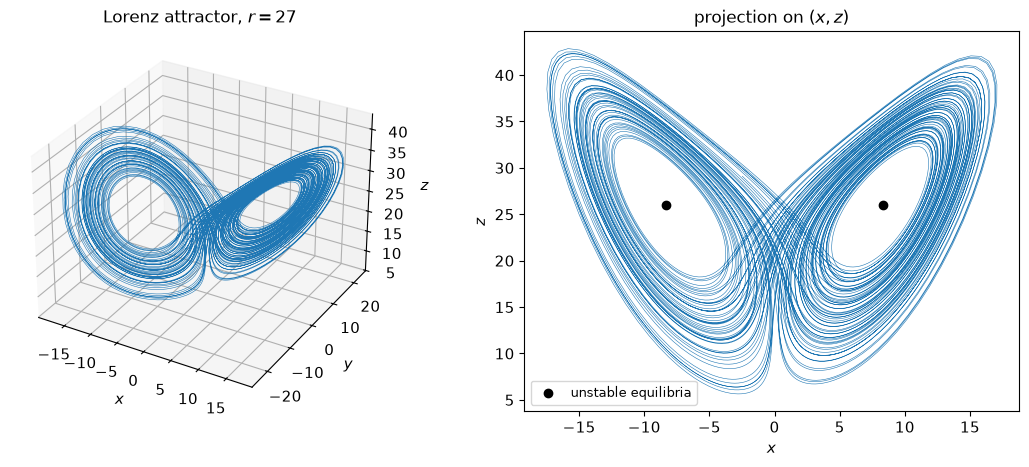

In [45]:
tr = m.run(keep=False, total=100, trans=10)
fig = plt.figure(figsize=(11, 4.8))
ax = fig.add_subplot(1, 2, 1, projection="3d")
ax.plot(tr["x"], tr["y"], tr["z"], lw=0.4, color="tab:blue")
ax.set(xlabel="$x$", ylabel="$y$", zlabel="$z$", title="Lorenz attractor, $r = 27$")
ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(tr["x"], tr["z"], lw=0.4, color="tab:blue")
c = np.sqrt(b * (27 - 1))
ax2.plot([-c, c], [26, 26], "ko", ms=6, label="unstable equilibria")
ax2.set(xlabel="$x$", ylabel="$z$", title="projection on $(x, z)$")
ax2.legend()
fig.tight_layout()
fig.savefig(FIG / "attractor.png")

### AUTO: equilibria in $r$

Start from the origin at $r = 0.5$, where everything decays to it. XPP's AUTO
switches branches at the pitchfork (BP) by itself, so the diagram holds the
origin and both families of steady rolls ($x > 0$ and $x < 0$), each with its
Hopf point. AUTO leaves $r$ at the end of the branch, so we put it back to 27.

AUTO: pitchfork at r = 1.000000; Hopf on the rolls at r = [24.73685]


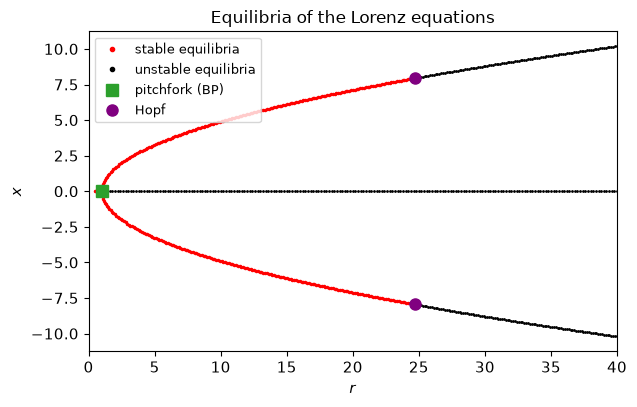

In [46]:
m.set(r=0.5)
m.run(total=200, x=0.1, y=0.1, z=0.1)
m.run_last(total=10)
eqs = m.auto.run("r", start="steady", ds=0.02, dsmax=0.2, parmin=0, parmax=40, nmax=500)
bp = eqs.special("BP")[0]
hbs = eqs.special("HB")
m.set(r=27)
print(f"AUTO: pitchfork at r = {bp.x:.6f}; Hopf on the rolls at r =",
      sorted({round(p.x, 5) for p in hbs}))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
xs = np.array([p.x for p in eqs])
us = np.array([p.u0["x"] for p in eqs])
st = np.array([p.stable for p in eqs])
ax.plot(xs[st], us[st], "r.", ms=3)
ax.plot(xs[~st], us[~st], "k.", ms=2)
ax.plot([], [], "r.", label="stable equilibria")
ax.plot([], [], "k.", label="unstable equilibria")
ax.plot(bp.x, bp.u0["x"], "s", color="tab:green", ms=8, label="pitchfork (BP)")
ax.plot([p.x for p in hbs], [p.u0["x"] for p in hbs], "o", color="purple", ms=8, label="Hopf")
ax.set(xlim=(0, 40), xlabel="$r$", ylabel="$x$", title="Equilibria of the Lorenz equations")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "bifurcation.png")

### Sensitive dependence: separation of nearby orbits

40 pairs of orbits start $10^{-8}$ apart at points spread over the attractor.
One pair's separation $d(t)$ wobbles a lot, so we average $\ln d$ over the
pairs; the average grows like $\lambda t$ until the distance is as big as the
attractor. XPP keeps its data in single precision (about 7 digits), so
distances below about $10^{-5}$ are rounding noise in the stored orbits: the
fit uses only $10^{-5} < d < 10^{-1}$.

largest Lyapunov exponent from the slope: lambda = 0.917


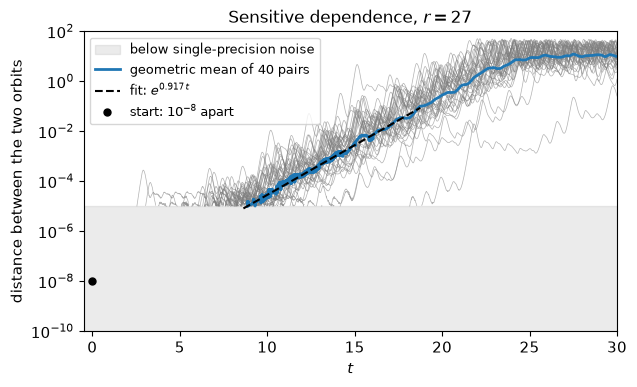

In [47]:
long = m.run(keep=False, total=1000, trans=10)
starts = long.array[::1500, 1:4][:40]
lnd = []
fig, ax = plt.subplots(figsize=(6.5, 4))
for x0, y0, z0 in starts:
    a1 = m.run(keep=False, total=30, x=x0, y=y0, z=z0)
    a2 = m.run(keep=False, total=30, x=x0 + 1e-8, y=y0, z=z0)
    sep = np.sqrt(sum((a1[v] - a2[v])**2 for v in "xyz"))
    ax.semilogy(a1.t, np.where(sep > 1e-5, sep, np.nan), lw=0.5, color="tab:gray", alpha=0.6)
    lnd.append(np.log(np.maximum(sep, 1e-12)))
t, lnd = a1.t, np.mean(lnd, axis=0)
fit = (lnd > np.log(1e-5)) & (np.cumsum(lnd > np.log(1e-1)) == 0)
lam, c0 = np.polyfit(t[fit], lnd[fit], 1)
ax.axhspan(1e-10, 1e-5, color="tab:gray", alpha=0.15, label="below single-precision noise")
ax.semilogy(t, np.where(lnd > np.log(1e-5), np.exp(lnd), np.nan), color="tab:blue", lw=2,
            label="geometric mean of 40 pairs")
ax.semilogy(t[fit], np.exp(c0 + lam * t[fit]), "k--", lw=1.5, label=f"fit: $e^{{{lam:.3f}\\,t}}$")
ax.plot(0, 1e-8, "ko", ms=5, label="start: $10^{-8}$ apart")
ax.set(xlim=(-0.5, 30), ylim=(1e-10, 1e2), xlabel="$t$", ylabel="distance between the two orbits",
       title="Sensitive dependence, $r = 27$")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "separation.png")
print(f"largest Lyapunov exponent from the slope: lambda = {lam:.3f}")

### Lorenz's return map

Successive maxima of $z$ plotted against each other, $z_{n+1}$ against $z_n$,
lie close to a single tent-shaped curve: the chaos is essentially
one-dimensional.

622 maxima of z, between 29.92 and 44.98


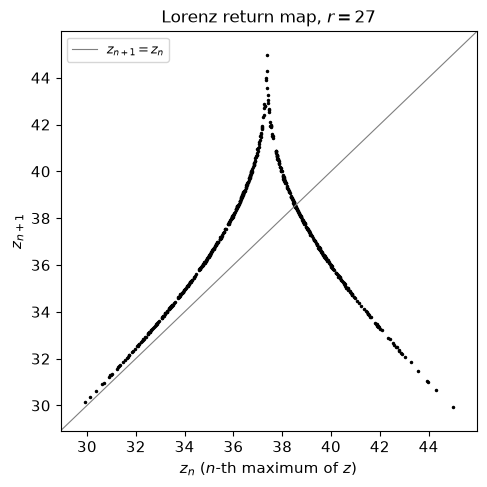

In [48]:
z = m.run(keep=False, total=500, trans=20)["z"]
k = np.where((z[1:-1] > z[:-2]) & (z[1:-1] > z[2:]))[0] + 1
zmax = z[k]
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(zmax[:-1], zmax[1:], "k.", ms=3)
lims = (zmax.min() - 1, zmax.max() + 1)
ax.plot(lims, lims, color="tab:gray", lw=0.8, label="$z_{n+1} = z_n$")
ax.set(xlim=lims, ylim=lims, xlabel="$z_n$ ($n$-th maximum of $z$)", ylabel="$z_{n+1}$",
       title="Lorenz return map, $r = 27$")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "return_map.png")
print(f"{len(zmax)} maxima of z, between {zmax.min():.2f} and {zmax.max():.2f}")

### Checks

* The origin has the eigenvalue
  $\tfrac12\bigl(-(s+1) + \sqrt{(s-1)^2 + 4sr}\bigr)$, which is zero at $r = 1$:
  the pitchfork.
* On the rolls $x = y = \pm\sqrt{b(r-1)}$, $z = r - 1$, the characteristic
  polynomial is
  $\lambda^3 + (s+b+1)\lambda^2 + b(s+r)\lambda + 2bs(r-1)$; it has a pair
  $\pm i\omega$ when

$$
r_{\mathrm{H}} = \frac{s\,(s + b + 3)}{s - b - 1} \approx 24.74 .
$$

* At $r = 27$ the roll is at $x = \sqrt{26b}$ and unstable.
* The largest Lyapunov exponent of the Lorenz attractor is about 0.9 (0.906 at
  $r = 28$, slightly less at $r = 27$); ours is a finite-time estimate from 40
  pairs.

In [49]:
check("pitchfork at r = 1 (exact)", bp.x, 1.0, 1e-4)
r_hopf = s * (s + b + 3) / (s - b - 1)
check("Hopf of the rolls (exact)", hbs[0].x, r_hopf, 1e-3)
eq = m.equilibrium({"x": 8, "y": 8, "z": 26})
check("steady roll x = sqrt(b(r-1)) at r = 27 (exact)", eq.x["X"], np.sqrt(b * 26), 1e-6)
check("steady roll is unstable at r = 27 (0 = unstable)", float(eq.stable), 0, 0)
check("Lyapunov exponent from the separation (about 0.9)", lam, 0.9, 0.1)
checks_done()

  ok   pitchfork at r = 1 (exact): 1 (expected 1)
  ok   Hopf of the rolls (exact): 24.7369 (expected 24.7368)


  ok   steady roll x = sqrt(b(r-1)) at r = 27 (exact): 8.32666 (expected 8.32666)
  ok   steady roll is unstable at r = 27 (0 = unstable): 0 (expected 0)
  ok   Lyapunov exponent from the separation (about 0.9): 0.916535 (expected 0.9)

07_lorenz: 5/5 checks passed


## Summary

All checks of this notebook:

In [50]:
for name, r in results.items():
    print(f"{name:40s} {sum(r):3d}/{len(r)}")
n_ok = sum(sum(r) for r in results.values())
n = sum(len(r) for r in results.values())
print(f"\n{n_ok}/{n} checks passed")

01_fitzhugh-nagumo                         5/5
02_toggle-switch                          10/10
03_bouncing-ball                           5/5
04_integrate-and-fire                      8/8
05_logistic-map                            8/8
06_henon-map                               7/7
07_lorenz                                  5/5

48/48 checks passed
